In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("car data.csv")

In [3]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

In [4]:
# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print(df.head())
print(df.shape)

  Car_Name  Year  Selling_Price  Present_Price  Kms_Driven Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Seller_Type Transmission  Owner  
0      Dealer       Manual      0  
1      Dealer       Manual      0  
2      Dealer       Manual      0  
3      Dealer       Manual      0  
4      Dealer       Manual      0  
(301, 9)


C:\Users\Arati\AppData\Local\Temp\ipykernel_23984\570878741.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [6]:
# ============================================================
# 3. REMOVE BIKE DATA
# ============================================================

bike_keywords = [
    "royal enfield", "ktm", "bajaj", "yamaha",
    "tvs", "hero", "honda cb", "honda cbr",
    "honda activa", "honda dream", "honda hornet",
    "honda unicorn", "honda shine", "honda twister",
    "honda karizma", "honda trigger", "hyosung",
    "um renegade", "mahindra mojo"
]

bike_mask = df["Car_Name"].str.lower().apply(
    lambda x: any(word in x for word in bike_keywords)
)
df = df[~bike_mask].copy()

print("After removing bikes:", df.shape)

After removing bikes: (204, 9)


In [7]:
# 4. HANDLE MISSING VALUES
# ============================================================

# Numerical columns
numeric_cols = [
    "Year",
    "Selling_Price",
    "Present_Price",
    "Kms_Driven",
    "Owner"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())

In [8]:
# Categorical columns
categorical_cols = [
    "Car_Name",
    "Fuel_Type",
    "Seller_Type",
    "Transmission"
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
# 5. REMOVE INVALID VALUES
# ============================================================

df = df[
    (df["Year"] > 0) &
    (df["Selling_Price"] > 0) &
    (df["Present_Price"] > 0) &
    (df["Kms_Driven"] >= 0)
]

print("After cleaning:", df.shape)

After cleaning: (204, 9)


In [10]:
# ============================================================
# 6. FEATURE ENGINEERING
# ============================================================

# Car age
df["Car_Age"] = 2026 - df["Year"]

# Kilometers per year
df["Kms_Per_Year"] = (
    df["Kms_Driven"] /
    df["Car_Age"].clip(lower=1)
)

print(df[[
    "Car_Age",
    "Kms_Per_Year"
]].head())



   Car_Age  Kms_Per_Year
0       12   2250.000000
1       13   3307.692308
2        9    766.666667
3       15    346.666667
4       12   3537.500000


In [11]:
df.columns

Index(['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven',
       'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner', 'Car_Age',
       'Kms_Per_Year'],
      dtype='str')

In [15]:
X = df[
    [
        "Car_Name",
        "Present_Price",
        "Kms_Driven",
        "Fuel_Type",
        "Seller_Type",
        "Transmission",
        "Owner",
        "Car_Age",
        "Kms_Per_Year"
    ]
]

y = df["Selling_Price"]

In [16]:
# ============================================================
# 8. CONVERT CATEGORICAL DATA INTO NUMBERS
# ============================================================

X = pd.get_dummies(
    X,
    columns=[
        "Car_Name",
        "Fuel_Type",
        "Seller_Type",
        "Transmission"
    ],
    drop_first=True
)

In [17]:
# ============================================================
# 9. TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (163, 48)
Testing data: (41, 48)


In [18]:
# ============================================================
# 10. RANDOM FOREST MODEL
# ============================================================

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [19]:
# ============================================================
# 11. PREDICTION
# ============================================================

y_pred = model.predict(X_test)

In [20]:
# 12. MODEL EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")

print("MAE:", round(mae, 2), "Lakh")
print("RMSE:", round(rmse, 2), "Lakh")
print("R2 Score:", round(r2, 4))


========== MODEL EVALUATION ==========
MAE: 1.03 Lakh
RMSE: 2.62 Lakh
R2 Score: 0.8306


In [21]:
# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nTop 5 Important Features:")
print(importance.head(5))



Top 5 Important Features:
              Feature  Importance
0       Present_Price    0.773612
3             Car_Age    0.115532
27  Car_Name_fortuner    0.037368
1          Kms_Driven    0.025694
4        Kms_Per_Year    0.020539


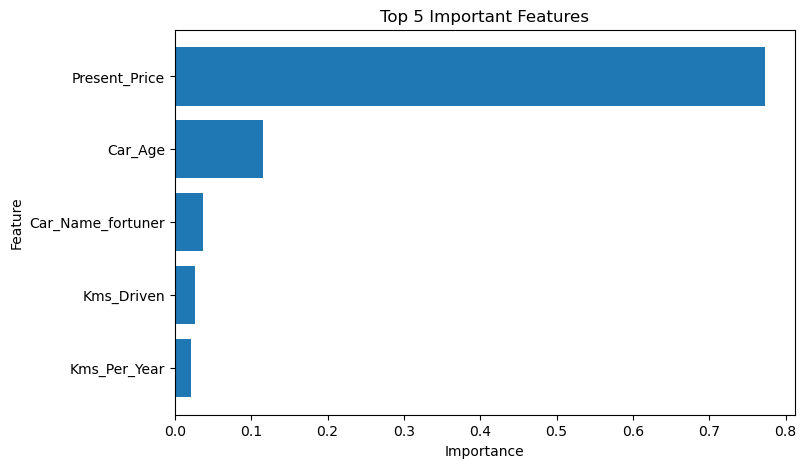

In [22]:
# ============================================================
# 14. FEATURE IMPORTANCE GRAPH
# ============================================================

top5 = importance.head(5)

plt.figure(figsize=(8, 5))

plt.barh(
    top5["Feature"],
    top5["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 5 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [23]:
# ============================================================
# 15. PREDICT PRICE OF NEW CAR
# ============================================================

new_car = pd.DataFrame([{
    "Car_Name": "city",
    "Present_Price": 10.0,
    "Kms_Driven": 25000,
    "Fuel_Type": "Petrol",
    "Seller_Type": "Dealer",
    "Transmission": "Manual",
    "Owner": 0,
    "Car_Age": 4,
    "Kms_Per_Year": 6250
}])

In [24]:
# Convert new car into same format
new_car = pd.get_dummies(
    new_car,
    columns=[
        "Car_Name",
        "Fuel_Type",
        "Seller_Type",
        "Transmission"
    ],
    drop_first=True
)

In [26]:
# Make columns same as training data
new_car = new_car.reindex(
    columns=X.columns,
    fill_value=0
)


# Predict
predicted_price = model.predict(new_car)[0]

print("\n========== NEW CAR PREDICTION ==========")

print(
    "Predicted Selling Price: ₹",
    round(predicted_price * 100000, 2))


========== NEW CAR PREDICTION ==========
Predicted Selling Price: ₹ 780895.0
